# 08 — Sampler microbenchmark: vLLM's fused sampler vs. top-k self-conditioning

**Question:** inside a real serving engine, how much does replacing the full self-conditioning hint with a top-k hint save, in time and memory, as the batch grows?

**No model is loaded.** The sampler only needs (a) the logits and (b) the embedding table. We use real logits saved by notebook 04 and the real embedding table read from the checkpoint. This runs on **one A100**.

| path | what it does per denoising step |
|---|---|
| `vllm` | vLLM's fused Triton kernel: one pass for argmax + sample + entropy, a second pass writing the softmax in bf16; then the full hint matmul `probs @ E * sqrt(d)` (262,144 × 2,816) |
| `topk` (ours) | the same kernel **without** writing probs; then `torch.topk` + a k-row hint sum (k = 64 or 256) |
| `hf` | the Hugging Face / diffusers stock path, for reference (several full fp32 passes) |

The commit / re-noise / stop kernel is identical in `vllm` and `topk` (it only reads the 256 entropies), so it is not timed.

**What we measure**
1. **Correctness:** the copied kernel matches a float64 reference; top-k hint error vs. the full hint.
2. **Time per step** (median of 10, CUDA events) for each path and each part, at batch 1–64.
3. **Peak extra memory** each path adds on top of its inputs.
4. **Context:** the LM-head matmul time, to see the sampler's share of the step.

In [1]:
import os, sys, subprocess
if 'torch' in sys.modules:
    raise RuntimeError('Restart the kernel, then run this cell first.')
GPU = None        # e.g. '0'; None = the GPU with the most free memory
if GPU is None:
    rows = subprocess.run(['nvidia-smi', '--query-gpu=index,memory.free', '--format=csv,noheader,nounits'],
                          capture_output=True, text=True, check=True).stdout.strip().splitlines()
    if os.environ.get('SLURM_JOB_ID') and os.environ.get('CUDA_VISIBLE_DEVICES'):   # under Slurm: only the GPUs this job was given
        rows = [r for r in rows if r.split(', ')[0] in os.environ['CUDA_VISIBLE_DEVICES'].split(',')]
    free = sorted(((int(i), int(f) / 1024) for i, f in (r.split(', ') for r in rows)), key=lambda x: -x[1])
    print('free GB per GPU:', {i: round(f, 1) for i, f in free})
    GPU = str(free[0][0])
os.environ['CUDA_VISIBLE_DEVICES'] = GPU
print('using GPU', GPU)

free GB per GPU: {0: 39.5, 6: 37.4, 2: 17.8, 7: 16.0, 4: 15.6, 5: 15.3, 3: 13.6, 1: 1.0}
using GPU 0


In [2]:
import math, time, importlib
import torch, triton
import pandas as pd
import matplotlib.pyplot as plt
import hint_bench as hb          # hint_bench.py must sit next to this notebook
importlib.reload(hb)
dev = 'cuda'
print('torch', torch.__version__, '| triton', triton.__version__, '|', torch.cuda.get_device_name(0))
print('free GB:', round(torch.cuda.mem_get_info()[0] / 2**30, 1))

MODEL_ID = 'google/diffusiongemma-26B-A4B-it'
LOGITS_GLOB = './runs/nb04/step_*.pt'      # saved by notebook 04 (adjust if they live elsewhere)
CL = 256                                    # canvas length
KS = [64, 256]
BATCHES = [1, 2, 4, 8, 16, 32, 64]

torch 2.14.1+cu130 | triton 3.8.0 | NVIDIA A100-PCIE-40GB
free GB: 39.1


## 1. Inputs: the embedding table and real logits

In [3]:
t0 = time.time()
E, key = hb.load_embedding_table(MODEL_ID, dev)
scale = torch.tensor(E.shape[1] ** 0.5, dtype=E.dtype, device=dev)      # the decoder's embed_scale (~53)
E_sum = E.float().sum(0)
print(f'embedding table {key}: {tuple(E.shape)} {E.dtype}, {E.numel() * 2 / 2**30:.2f} GB, loaded in {time.time() - t0:.0f}s')

saved = hb.load_saved_logits(LOGITS_GLOB)
assert saved, f'no logits found at {LOGITS_GLOB}'
print(len(saved), 'saved steps:', [(tuple(L.shape), s) for L, s in saved])
V = E.shape[0]
assert saved[0][0].shape[-1] == V

/data/users/shreenis/private/VLA_experiments/.venv-2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


embedding table model.decoder.embed_tokens.weight: (262144, 2816) torch.bfloat16, 1.38 GB, loaded in 1s
6 saved steps: [((256, 262144), 0), ((256, 262144), 1), ((256, 262144), 2), ((256, 262144), 3), ((256, 262144), 4), ((256, 262144), 5)]


## 2. Correctness

* The copied vLLM kernel's entropy and argmax vs. a float64 reference (should agree to ~1e-5).
* The top-k hint vs. vLLM's full hint, as relative error per slot (‖topk − full‖ / ‖full‖), for each k and tail option. Notebook 07 measured ~0.2–0.5% at k = 64 against the Hugging Face hint.

In [4]:
L, temps = hb.make_batch(saved, 4, CL, dev)
inv = (1 / temps).repeat_interleave(CL)[:, None]
ref_lp = torch.log_softmax(L.double() * inv.double(), -1)
ref_ent = -(ref_lp.exp() * ref_lp).sum(-1)
argmax, sample, ent, lse, probs = hb.row_stats(L, temps, CL, probs_dtype=E.dtype)
print('entropy  max |kernel - float64|:', float((ent.double() - ref_ent).abs().max()))
print('lse      max |kernel - float64|:', float((lse.double() - torch.logsumexp(L.double() * inv.double(), -1)).abs().max()))
print('argmax   mismatches:', int((argmax != L.argmax(-1)).sum()), 'of', L.shape[0], '(ties in bf16-derived logits can differ)')
del ref_lp

full = hb.path_vllm(L, temps, CL, E, scale)['hint'].float()
nf = full.norm(dim=-1).clamp_min(1e-6)
rows = []
for k in KS:
    for tail in ('drop', 'renorm', 'mean'):
        h = hb.topk_hint(L, temps, CL, lse, E, scale, k, tail, E_sum).float()
        rel = ((h - full).norm(dim=-1) / nf)
        rows.append(dict(k=k, tail=tail, rel_err_mean_pct=100 * float(rel.mean()), rel_err_p99_pct=100 * float(rel.quantile(0.99))))
print(pd.DataFrame(rows).to_string(index=False, float_format='{:.3f}'.format))
del L, full, probs

entropy  max |kernel - float64|: 8.447572670267078e-07
lse      max |kernel - float64|: 2.4992759719566493e-06
argmax   mismatches: 0 of 1024 (ties in bf16-derived logits can differ)
  k   tail  rel_err_mean_pct  rel_err_p99_pct
 64   drop             0.097            1.054
 64 renorm             0.090            0.762
 64   mean             0.096            1.015
256   drop             0.069            0.374
256 renorm             0.070            0.389
256   mean             0.069            0.374


## 3. Time and memory vs. batch size

For each batch size B (B sequences × 256 slots), we build the logits once and time each path and its parts. If a path runs out of memory it is recorded as `OOM`; that is a result, not an error. Inputs alone take B × 268 MB, so B = 64 needs ~17 GB before any path runs.

In [5]:
RUN_HF = True        # the stock path needs several full fp32 copies; it will OOM at large B
results = []
for B in BATCHES:
    need = B * CL * V * 4 / 2**30
    if need * 1.6 > torch.cuda.mem_get_info()[0] / 2**30:
        print(f'B={B}: skipped (inputs alone {need:.1f} GB)'); continue
    L, temps = hb.make_batch(saved, B, CL, dev)
    _, _, _, lse, _ = hb.row_stats(L, temps, CL)
    row = dict(B=B)
    tests = {
        'vllm_total':        lambda: hb.path_vllm(L, temps, CL, E, scale),
        'vllm_stats+probs':  lambda: hb.row_stats(L, temps, CL, probs_dtype=E.dtype),
        'stats_only':        lambda: hb.row_stats(L, temps, CL),
    }
    probs_once = hb.row_stats(L, temps, CL, probs_dtype=E.dtype)[4]
    tests['vllm_hint_matmul'] = lambda: torch.matmul(probs_once, E) * scale
    for k in KS:
        tests[f'topk{k}_total'] = (lambda k=k: hb.path_topk(L, temps, CL, E, scale, k, 'renorm'))
        tests[f'topk{k}_topk'] = (lambda k=k: torch.topk(L, k, dim=-1))
        tests[f'topk{k}_hint'] = (lambda k=k: hb.topk_hint(L, temps, CL, lse, E, scale, k, 'renorm'))
    if RUN_HF:
        tests['hf_total'] = lambda: hb.path_hf(L, temps, CL, E, scale)
    hidden = torch.randn(B * CL, E.shape[1], dtype=E.dtype, device=dev)
    tests['context_lm_head'] = lambda: torch.matmul(hidden, E.t())
    for name, fn in tests.items():
        try:
            row[name + '_ms'] = hb.time_cuda(fn)
            if name.endswith('_total') or name == 'context_lm_head':
                row[name + '_mem_gb'] = hb.peak_extra_gb(fn)
        except torch.OutOfMemoryError:
            row[name + '_ms'] = float('nan'); row[name + '_mem_gb'] = float('nan')
            torch.cuda.empty_cache()
    del probs_once, hidden, L
    torch.cuda.empty_cache()
    results.append(row)
    print(f"B={B:3d} | vllm {row['vllm_total_ms']:7.2f} ms | topk64 {row['topk64_total_ms']:7.2f} ms | "
          f"hf {row.get('hf_total_ms', float('nan')):7.2f} ms | LM head {row['context_lm_head_ms']:7.2f} ms")
res = pd.DataFrame(results)
os.makedirs('./runs/nb08', exist_ok=True)
res.to_csv('./runs/nb08/sampler_bench.csv', index=False)

B=  1 | vllm    4.01 ms | topk64    3.95 ms | hf   15.00 ms | LM head    1.63 ms
B=  2 | vllm    5.41 ms | topk64    5.59 ms | hf   28.70 ms | LM head    3.35 ms
B=  4 | vllm   10.87 ms | topk64   10.20 ms | hf   56.06 ms | LM head    7.40 ms
B=  8 | vllm   21.13 ms | topk64   19.42 ms | hf  111.46 ms | LM head   14.42 ms
B= 16 | vllm   43.70 ms | topk64   38.57 ms | hf  223.15 ms | LM head   28.26 ms


[W1124 03:02:03.810692216 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 8589934592 bytes (free: 1446051840, total: 42404806656).
[W1124 03:02:03.855240402 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 8589934592 bytes (free: 1538326528, total: 42404806656).


B= 32 | vllm   94.42 ms | topk64   81.54 ms | hf     nan ms | LM head   56.31 ms


[W1124 03:02:25.668721869 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 17179869184 bytes (free: 14085586944, total: 42404806656).
[W1124 03:02:25.678761148 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 17179869184 bytes (free: 14423228416, total: 42404806656).


B= 64 | vllm  198.47 ms | topk64  162.95 ms | hf     nan ms | LM head  114.12 ms


## 4. Results

In [6]:
pd.set_option('display.float_format', '{:.2f}'.format)
cols = ['B', 'vllm_total_ms', 'topk64_total_ms', 'topk256_total_ms', 'hf_total_ms', 'context_lm_head_ms']
print('Time per denoising step (ms)')
print(res[[c for c in cols if c in res]].to_string(index=False))

print('\nWhere vLLM\'s time goes (ms)')
print(res[['B', 'stats_only_ms', 'vllm_stats+probs_ms', 'vllm_hint_matmul_ms']].to_string(index=False))
print('\nWhere top-k\'s time goes (ms)')
print(res[['B', 'stats_only_ms', 'topk64_topk_ms', 'topk64_hint_ms']].to_string(index=False))

s = pd.DataFrame({'B': res.B,
                  'speedup vs vllm (k=64)': res.vllm_total_ms / res.topk64_total_ms,
                  'speedup vs vllm (k=256)': res.vllm_total_ms / res.topk256_total_ms,
                  'saved ms/step (k=64)': res.vllm_total_ms - res.topk64_total_ms,
                  'saved as % of LM head': 100 * (res.vllm_total_ms - res.topk64_total_ms) / res.context_lm_head_ms})
print('\nSummary'); print(s.to_string(index=False))

print('\nPeak extra memory per step (GB)')
mcols = ['B', 'vllm_total_mem_gb', 'topk64_total_mem_gb', 'topk256_total_mem_gb', 'hf_total_mem_gb']
print(res[[c for c in mcols if c in res]].to_string(index=False))

Time per denoising step (ms)
 B  vllm_total_ms  topk64_total_ms  topk256_total_ms  hf_total_ms  context_lm_head_ms
 1           4.01             3.95              3.43        15.00                1.63
 2           5.41             5.59              5.98        28.70                3.35
 4          10.87            10.20             11.59        56.06                7.40
 8          21.13            19.42             22.56       111.46               14.42
16          43.70            38.57             45.36       223.15               28.26
32          94.42            81.54             95.16          NaN               56.31
64         198.47           162.95            190.37          NaN              114.12

Where vLLM's time goes (ms)
 B  stats_only_ms  vllm_stats+probs_ms  vllm_hint_matmul_ms
 1           1.65                 1.94                 2.07
 2           1.97                 2.50                 3.05
 4           3.66                 4.76                 6.33
 8           6

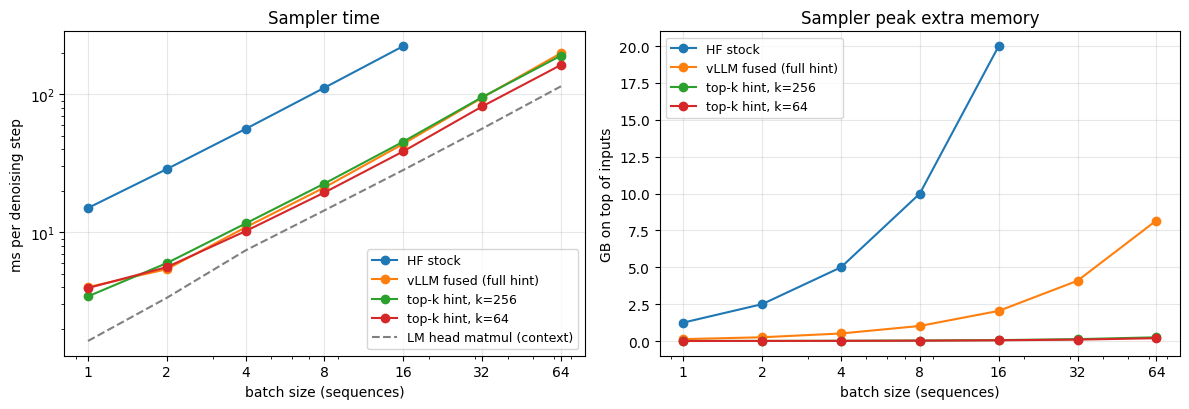

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for name, lab in [('hf_total', 'HF stock'), ('vllm_total', 'vLLM fused (full hint)'),
                  ('topk256_total', 'top-k hint, k=256'), ('topk64_total', 'top-k hint, k=64')]:
    if name + '_ms' in res:
        ax[0].plot(res.B, res[name + '_ms'], marker='o', label=lab)
        ax[1].plot(res.B, res[name + '_mem_gb'], marker='o', label=lab)
ax[0].plot(res.B, res.context_lm_head_ms, ls='--', color='gray', label='LM head matmul (context)')
ax[0].set(xscale='log', yscale='log', xlabel='batch size (sequences)', ylabel='ms per denoising step', title='Sampler time')
ax[1].set(xscale='log', xlabel='batch size (sequences)', ylabel='GB on top of inputs', title='Sampler peak extra memory')
for a in ax:
    a.set_xticks(res.B); a.set_xticklabels(res.B); a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.savefig('./runs/nb08/sampler_bench.png', dpi=150); plt.show()

## How to read the results

1. **Correctness first.** The kernel's entropy must match float64 to ~1e-5, and the top-k hint error should be well under 1% at k = 64 (renorm best). If not, stop and check.
2. **The headline is `speedup vs vllm` and `saved ms/step`.** vLLM's time is mostly two things: the bf16 probs write (`vllm_stats+probs` − `stats_only`) and the hint matmul. Top-k removes both and adds `topk` + a tiny `hint`.
3. **`saved as % of LM head`** puts the saving in context: the LM-head matmul is a fixed part of every step. A saving comparable to the LM head is a large fraction of the whole step.
4. **Memory:** vLLM keeps a [B·256 × 262,144] bf16 probs tensor (134 MB per sequence); top-k keeps [B·256 × k].
5. **What this does not include:** the 30 layers. The end-to-end effect is measured later inside vLLM (tensor parallel 2), where `saved ms/step` is compared with the full step time.
6. **Known extra cost in `topk`:** `torch.topk` reads the logits a second time. Folding the top-k into the stats kernel (one pass) is the next step; `topk64_topk_ms` is the most that would save.

## 5. Fused top-k: statistics and top-k in one pass

Section 4 showed that `torch.topk` (a separate pass over all 262,144 logits) costs almost as much as the hint matmul it lets us skip. The kernel `_row_stats_topk_kernel` in `hint_bench.py` does vLLM's statistics pass **and** keeps a running top-k list in the same pass, so the logits are read once.

* The argmax / sample / entropy code is vLLM's, with the same random numbers, so the commit, re-noise and stop decisions are identical.
* The running top-k only does work when a block's maximum can enter the list; after the first few blocks this is rare.

Two more variants test a hypothesis from section 4: vLLM's statistics pass reaches only ~20% of the A100's memory bandwidth, possibly because it draws a random number and takes two logarithms for **every** logit (Gumbel-max sampling).
* `stats_nogumbel`: vLLM's pass without the per-logit random numbers (timing only).
* `fused_nogumbel`: the fused pass without them, sampling the token from the top-k probabilities instead. That is a timing estimate: an exact sampler also needs a rare draw from the tail (probability = tail mass), which is omitted here.

**Check first:** decisions identical to vLLM's kernel, top-k identical to `torch.topk`, and the hint error as in section 2.

In [8]:
importlib.reload(hb)
K = 64
L, temps = hb.make_batch(saved, 4, CL, dev)
a1, s1, e1, lse1, _ = hb.row_stats(L, temps, CL, seed=7)
try:
    a2, s2, e2, ti, tp = hb.row_stats_topk(L, temps, CL, k=K, seed=7)
except Exception as ex:
    raise RuntimeError(f'fused kernel failed to compile or run: {type(ex).__name__}: {ex}')
print('argmax  identical to vLLM kernel:', bool(torch.equal(a1, a2)))
print('sample  identical to vLLM kernel:', bool(torch.equal(s1, s2)))
print('entropy max |diff| vs vLLM kernel:', float((e1 - e2).abs().max()))

vals, idx = torch.topk(L, K, dim=-1)
same_set = (torch.sort(ti.long(), dim=-1).values == torch.sort(idx, dim=-1).values).all(dim=-1)   # per row: same set of ids
print(f'top-{K} id set identical to torch.topk: {int(same_set.sum())} / {L.shape[0]} rows  (differences can only be exact ties)')
inv = (1 / temps).repeat_interleave(CL)[:, None]
p_ref = torch.exp(vals * inv - lse1[:, None])
print('top-k prob sum max |diff| vs torch.topk path:', float((tp.sum(-1) - p_ref.sum(-1)).abs().max()))

full = hb.path_vllm(L, temps, CL, E, scale)['hint'].float()
h = hb.hint_from_topk(ti, tp, E, scale).float()
rel = (h - full).norm(dim=-1) / full.norm(dim=-1).clamp_min(1e-6)
print(f'fused top-{K} hint vs vLLM full hint: mean {100 * float(rel.mean()):.3f}%  p99 {100 * float(rel.quantile(0.99)):.3f}%')
del L, full

argmax  identical to vLLM kernel: True
sample  identical to vLLM kernel: True
entropy max |diff| vs vLLM kernel: 0.0
top-64 id set identical to torch.topk: 480 / 1024 rows  (differences can only be exact ties)
top-k prob sum max |diff| vs torch.topk path: 3.6954879760742188e-06
fused top-64 hint vs vLLM full hint: mean 0.090%  p99 0.754%


In [9]:
fused_rows = []
for B in BATCHES:
    need = B * CL * V * 4
    if need * 1.6 > torch.cuda.mem_get_info()[0]:
        print(f'B={B}: skipped'); continue
    L, temps = hb.make_batch(saved, B, CL, dev)
    row = dict(B=B)
    tests = {
        'vllm_total':          lambda: hb.path_vllm(L, temps, CL, E, scale),
        'topk64_unfused':      lambda: hb.path_topk(L, temps, CL, E, scale, 64, 'renorm'),
        'fused64_total':       lambda: hb.path_topk_fused(L, temps, CL, E, scale, 64),
        'fused64_nogumbel':    lambda: hb.path_topk_fused_nogumbel(L, temps, CL, E, scale, 64),
        'stats_only':          lambda: hb.row_stats(L, temps, CL),
        'stats_nogumbel':      lambda: hb.row_stats(L, temps, CL, do_sample=False),
        'fused64_stats':       lambda: hb.row_stats_topk(L, temps, CL, 64),
        'fused64_stats_nogumbel': lambda: hb.row_stats_topk(L, temps, CL, 64, do_sample=False),
    }
    for name, fn in tests.items():
        try:
            row[name + '_ms'] = hb.time_cuda(fn)
            if name.endswith(('_total', '_unfused', '_nogumbel')) and not name.startswith('stats'):
                row[name + '_mem_gb'] = hb.peak_extra_gb(fn)
        except torch.OutOfMemoryError:
            row[name + '_ms'] = float('nan'); torch.cuda.empty_cache()
    gb = need / 1e9
    for name in ('stats_only', 'stats_nogumbel', 'fused64_stats', 'fused64_stats_nogumbel'):
        row[name + '_GBps'] = gb / (row[name + '_ms'] / 1e3)
    fused_rows.append(row)
    print(f"B={B:3d} | vllm {row['vllm_total_ms']:7.2f} | unfused {row['topk64_unfused_ms']:7.2f} | "
          f"fused {row['fused64_total_ms']:7.2f} | fused no-gumbel {row['fused64_nogumbel_ms']:7.2f} ms")
    del L; torch.cuda.empty_cache()
fres = pd.DataFrame(fused_rows)
fres.to_csv('./runs/nb08/fused_bench.csv', index=False)

B=  1 | vllm    2.93 | unfused    3.14 | fused    1.70 | fused no-gumbel    0.88 ms
B=  2 | vllm    5.51 | unfused    5.47 | fused    2.66 | fused no-gumbel    1.33 ms
B=  4 | vllm   11.09 | unfused   10.08 | fused    5.07 | fused no-gumbel    2.44 ms
B=  8 | vllm   21.79 | unfused   19.31 | fused    9.69 | fused no-gumbel    4.58 ms
B= 16 | vllm   43.88 | unfused   38.60 | fused   19.26 | fused no-gumbel    9.00 ms
B= 32 | vllm   92.74 | unfused   81.60 | fused   38.60 | fused no-gumbel   17.68 ms
B= 64 | vllm  197.57 | unfused  163.01 | fused   76.68 | fused no-gumbel   35.44 ms


Time per denoising step (ms)
 B  vllm_total_ms  topk64_unfused_ms  fused64_total_ms  fused64_nogumbel_ms
 1           2.93               3.14              1.70                 0.88
 2           5.51               5.47              2.66                 1.33
 4          11.09              10.08              5.07                 2.44
 8          21.79              19.31              9.69                 4.58
16          43.88              38.60             19.26                 9.00
32          92.74              81.60             38.60                17.68
64         197.57             163.01             76.68                35.44

Speed-up vs vLLM
 B  unfused top-k  fused top-k  fused, no per-logit RNG (estimate)
 1           0.93         1.73                                3.32
 2           1.01         2.07                                4.14
 4           1.10         2.19                                4.55
 8           1.13         2.25                                4.76
16        

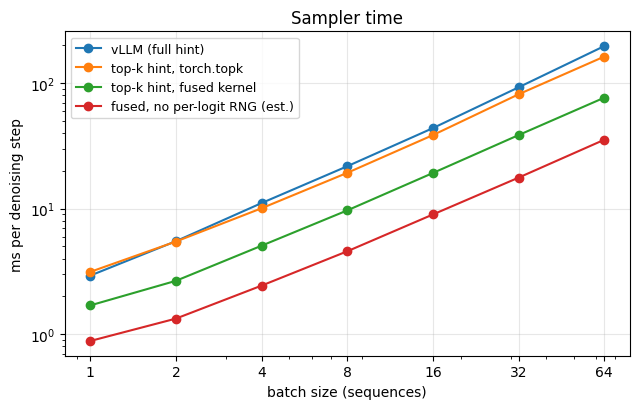

In [10]:
pd.set_option('display.float_format', '{:.2f}'.format)
print('Time per denoising step (ms)')
print(fres[['B', 'vllm_total_ms', 'topk64_unfused_ms', 'fused64_total_ms', 'fused64_nogumbel_ms']].to_string(index=False))
print('\nSpeed-up vs vLLM')
print(pd.DataFrame({'B': fres.B,
                    'unfused top-k': fres.vllm_total_ms / fres.topk64_unfused_ms,
                    'fused top-k': fres.vllm_total_ms / fres.fused64_total_ms,
                    'fused, no per-logit RNG (estimate)': fres.vllm_total_ms / fres.fused64_nogumbel_ms}).to_string(index=False))
print('\nStatistics pass alone: ms and achieved read bandwidth (A100 40 GB peak ~1,555 GB/s)')
print(fres[['B', 'stats_only_ms', 'stats_only_GBps', 'stats_nogumbel_ms', 'stats_nogumbel_GBps',
            'fused64_stats_ms', 'fused64_stats_GBps', 'fused64_stats_nogumbel_ms', 'fused64_stats_nogumbel_GBps']].to_string(index=False))
print('\nPeak extra memory (GB)')
print(fres[['B'] + [c for c in fres if c.endswith('_mem_gb')]].to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for c, lab in [('vllm_total_ms', 'vLLM (full hint)'), ('topk64_unfused_ms', 'top-k hint, torch.topk'),
               ('fused64_total_ms', 'top-k hint, fused kernel'), ('fused64_nogumbel_ms', 'fused, no per-logit RNG (est.)')]:
    ax.plot(fres.B, fres[c], marker='o', label=lab)
ax.set(xscale='log', yscale='log', xlabel='batch size (sequences)', ylabel='ms per denoising step', title='Sampler time')
ax.set_xticks(fres.B); ax.set_xticklabels(fres.B); ax.grid(alpha=0.3); ax.legend(fontsize=9)
plt.tight_layout(); plt.savefig('./runs/nb08/fused_bench.png', dpi=150); plt.show()

### Reading section 5

1. **Checks:** argmax and samples identical to vLLM's kernel, the top-k id sets identical to `torch.topk` (except exact ties), hint error as in section 2. If any check fails, the timing numbers do not count.
2. **`fused top-k` speed-up vs vLLM** is the headline: it removes both the hint matmul and the separate `torch.topk` pass. Compare `fused64_stats_ms` with `stats_only_ms`: the gap is what the running top-k costs.
3. **Bandwidth columns:** if `stats_nogumbel` reaches a much higher GB/s than `stats_only`, the per-logit random numbers are what limits vLLM's pass, and sampling from the top-k (with an exact tail branch) is the next optimization.

## 6. Exact sampling from the top-k (no per-logit random numbers)

Section 5 showed vLLM's statistics pass is limited by drawing a random number for every logit (313 GB/s with them, 1,432 GB/s without). Here the fused kernel runs **without** them and the token is drawn exactly:

* with probability 1 − (tail mass): among the top-k, proportional to their probabilities;
* otherwise: from the tail, i.e. the full row with the top-k masked out (rare; only those rows are touched).

That gives exactly the same token distribution as softmax(logits / T), with different random numbers than vLLM's. Argmax and entropies (which drive commit and stop) stay bit-identical.

Cells: (1) the tie check for section 5's top-k sets, (2) a statistical test that the sampled tokens follow the true distribution, (3) timing.

In [11]:
# (1) Section 5 found 480/1024 rows with the same top-64 set as torch.topk. Are the other rows only exact ties at the cut-off?
importlib.reload(hb)
L, temps = hb.make_batch(saved, 4, CL, dev)
_, _, _, ti, tp = hb.row_stats_topk(L, temps, CL, k=64)
vals, idx = torch.topk(L, 64, dim=-1)
same_set = (torch.sort(ti.long(), dim=-1).values == torch.sort(idx, dim=-1).values).all(dim=-1)
ours_cut = L.gather(1, ti.long()).min(1).values
ref_cut = vals.min(1).values
bad = ~same_set
print('rows with a different id set:', int(bad.sum()), '/', L.shape[0])
print('same 64th-best value in every row:', bool(torch.equal(ours_cut, ref_cut)))
print('differing rows with >1 token at the cut-off value (a tie):',
      int(((L[bad] == ref_cut[bad, None]).sum(1) > 1).sum()), '/', int(bad.sum()))
print('our selected logits all >= the cut-off:', bool((L.gather(1, ti.long()) >= ref_cut[:, None]).all()))
del L

rows with a different id set: 544 / 1024
same 64th-best value in every row: True
differing rows with >1 token at the cut-off value (a tie): 544 / 544
our selected logits all >= the cut-off: True


In [12]:
# (2) Is the sampled-token distribution exact? Repeat a few real rows many times, sample once per copy, compare
#     the empirical frequencies with the true softmax probabilities. torch.multinomial on the full row is the reference.
N = 4000
L1, temps1 = hb.make_batch(saved[:1], 1, CL, dev)                 # step 0: the least certain step
tm1 = hb.tail_mass_from_topk(hb.row_stats_topk(L1, temps1, CL, k=64)[4])
test_rows = torch.argsort(tm1, descending=True)[:2].tolist()       # the two slots with the largest tail mass
g = torch.Generator(device=dev).manual_seed(0)
for r in test_rows:
    row = L1[r:r + 1]
    T = float(temps1[0])
    p_true = torch.softmax(row.float() / T, -1)[0]
    Lr = row.expand(N, -1).contiguous()
    tr = torch.full((1,), T, device=dev)
    _, _, _, ti_r, tp_r = hb.row_stats_topk(Lr, tr, N, k=64, do_sample=False)   # one "sequence" of N identical slots
    ours, n_tail = hb.sample_topk_exact(Lr, tr, N, ti_r, tp_r, g)
    ref = torch.multinomial(p_true, N, replacement=True, generator=g)
    top = torch.topk(p_true, 10).indices
    in_top64 = torch.zeros_like(p_true, dtype=torch.bool); in_top64[ti_r[0].long()] = True
    f = lambda s, t: float((s == t).float().mean())
    print(f'slot {r}: tail mass {float(tm1[r]):.4f} | tail draws ours {n_tail / N:.4f} | '
          f'outside top-64 in reference {float((~in_top64[ref]).float().mean()):.4f}')
    tbl = pd.DataFrame({'token': top.tolist(), 'p_true': p_true[top].tolist(),
                        'freq_ours': [f(ours, t) for t in top], 'freq_torch_multinomial': [f(ref, t) for t in top]})
    print(tbl.to_string(index=False, float_format='{:.4f}'.format))
    tv = lambda smp: 0.5 * float((torch.bincount(smp, minlength=p_true.numel()).float() / N - p_true).abs().sum())
    print(f'  total-variation distance to the true distribution: ours {tv(ours):.4f} | torch.multinomial {tv(ref):.4f} '
          f'(both are sampling noise at N={N}; they should be similar)\n')
    del Lr
del L1

slot 79: tail mass 0.0159 | tail draws ours 0.0125 | outside top-64 in reference 0.0108
 token  p_true  freq_ours  freq_torch_multinomial
   506  0.0773     0.0855                  0.0805
236819  0.0661     0.0680                  0.0653
   684  0.0649     0.0648                  0.0630
     1  0.0493     0.0548                  0.0438
236770  0.0456     0.0430                  0.0498
236743  0.0439     0.0415                  0.0373
236764  0.0422     0.0445                  0.0425
  4402  0.0406     0.0360                  0.0448
  1546  0.0375     0.0345                  0.0363
 53121  0.0375     0.0400                  0.0373
  total-variation distance to the true distribution: ours 0.0430 | torch.multinomial 0.0451 (both are sampling noise at N=4000; they should be similar)

slot 81: tail mass 0.0148 | tail draws ours 0.0143 | outside top-64 in reference 0.0138
 token  p_true  freq_ours  freq_torch_multinomial
236819  0.0863     0.0863                  0.0825
     1  0.0631     0.

In [13]:
# (3) Timing: vLLM vs fused top-k (vLLM's Gumbel sample) vs fused top-k with exact top-k sampling
exact_rows = []
for B in BATCHES:
    need = B * CL * V * 4
    if need * 1.6 > torch.cuda.mem_get_info()[0]:
        print(f'B={B}: skipped'); continue
    L, temps = hb.make_batch(saved, B, CL, dev)
    g = torch.Generator(device=dev).manual_seed(1)
    row = dict(B=B, tail_draw_pct=100 * hb.path_topk_exact(L, temps, CL, E, scale, 64, g)['n_tail'] / L.shape[0])
    tests = {
        'vllm_total':     lambda: hb.path_vllm(L, temps, CL, E, scale),
        'fused64_total':  lambda: hb.path_topk_fused(L, temps, CL, E, scale, 64),
        'exact64_total':  lambda: hb.path_topk_exact(L, temps, CL, E, scale, 64, g),
        'exact64_stats':  lambda: hb.row_stats_topk(L, temps, CL, 64, do_sample=False),
    }
    for name, fn in tests.items():
        try:
            row[name + '_ms'] = hb.time_cuda(fn)
            if name.endswith('_total'):
                row[name + '_mem_gb'] = hb.peak_extra_gb(fn)
        except torch.OutOfMemoryError:
            row[name + '_ms'] = float('nan'); torch.cuda.empty_cache()
    exact_rows.append(row)
    print(f"B={B:3d} | vllm {row['vllm_total_ms']:7.2f} | fused {row['fused64_total_ms']:7.2f} | "
          f"exact top-k sampling {row['exact64_total_ms']:7.2f} ms | tail draws {row['tail_draw_pct']:.2f}% of slots")
    del L; torch.cuda.empty_cache()
eres = pd.DataFrame(exact_rows)
eres.to_csv('./runs/nb08/exact_bench.csv', index=False)
print()
print(pd.DataFrame({'B': eres.B,
                    'speed-up fused (vLLM sampling)': eres.vllm_total_ms / eres.fused64_total_ms,
                    'speed-up fused + exact top-k sampling': eres.vllm_total_ms / eres.exact64_total_ms,
                    'exact stats pass GB/s': (eres.B * CL * V * 4 / 1e9) / (eres.exact64_stats_ms / 1e3)}).to_string(index=False, float_format='{:.2f}'.format))
print(eres[['B'] + [c for c in eres if c.endswith('_mem_gb')]].to_string(index=False, float_format='{:.2f}'.format))

B=  1 | vllm    2.88 | fused    1.78 | exact top-k sampling    1.51 ms | tail draws 0.39% of slots
B=  2 | vllm    5.70 | fused    3.08 | exact top-k sampling    2.00 ms | tail draws 0.20% of slots
B=  4 | vllm   11.10 | fused    5.37 | exact top-k sampling    3.09 ms | tail draws 0.10% of slots
B=  8 | vllm   21.49 | fused    9.95 | exact top-k sampling    5.18 ms | tail draws 0.05% of slots
B= 16 | vllm   43.69 | fused   19.30 | exact top-k sampling    9.66 ms | tail draws 0.05% of slots
B= 32 | vllm   93.80 | fused   38.47 | exact top-k sampling   18.27 ms | tail draws 0.06% of slots
B= 64 | vllm  196.48 | fused   76.53 | exact top-k sampling   35.93 ms | tail draws 0.04% of slots

 B  speed-up fused (vLLM sampling)  speed-up fused + exact top-k sampling  exact stats pass GB/s
 1                            1.61                                   1.91                 418.09
 2                            1.85                                   2.85                 566.19
 4             

### Reading section 6

1. **Tie check:** every differing row should have the same 64th-best value and a tie there; then the top-k sets are equivalent and the hint is unaffected.
2. **Distribution test:** for each test slot, `freq_ours` should match `p_true` about as closely as `freq_torch_multinomial` does, the tail-draw rate should match the tail mass, and the two total-variation distances should be similar. If ours is clearly larger, the sampler is not exact.
3. **Timing:** `speed-up fused + exact top-k sampling` is the version without per-logit random numbers. The bandwidth column shows how close its pass gets to the ~1,555 GB/s limit; the remaining gap is the running top-k's cost.